# ECG Beat Classifier: ConvNeXt-Atto on MIT-BIH (5 classes)
ECG branch of the *AI/ML Based Multi-Modal Cardiac Diagnostic System*.

**Setup before running:** Add dataset `shayanfazeli/heartbeat` | Accelerator: **GPU T4 x2** | Internet: **ON** (pretrained weights).

**Pipeline:** 1D beat (187 samples) -> 3 multi-resolution STFT spectrograms (computed on GPU) -> 224x224 3-channel image -> ImageNet-pretrained `convnext_atto` -> 5-class softmax.

**Anti-overfitting:** stratified train/val split, official test set untouched until the end, augmentation, label smoothing, drop-path, weight decay, early stopping on val macro-F1, clean train-vs-val-vs-test gap check.

**Imbalance:** power-weighted sampling (rare classes are seen more often) + label smoothing; selection by **macro-F1**, not plain accuracy.

**Time:** hard cap of 50 min on training (`time_budget_min`).

## 1. Setup and config

In [1]:
import os, time, json, glob, random, subprocess, sys
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, roc_curve, auc, balanced_accuracy_score)
from sklearn.preprocessing import label_binarize

try:
    import timm
except ImportError:                       # Kaggle usually has timm; install if missing
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
    import timm

SEED = 42
def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(SEED)

# ---- all tunable settings live here ----
CFG = dict(
    model_name="convnext_atto",
    img_size=224,
    batch_size=256,
    epochs=30,                 # upper limit; early stopping / time cap may stop sooner
    max_lr=1e-3,               # OneCycle peak LR (AdamW)
    weight_decay=0.05,
    samples_per_epoch=30000,   # sampled (class-rebalanced) beats per epoch
    sampler_power=0.75,        # 0 = natural distribution, 1 = fully balanced
    label_smoothing=0.05,
    drop_rate=0.2,
    drop_path_rate=0.1,
    patience=6,                # early-stopping patience (epochs) on val macro-F1
    time_budget_min=50,        # hard stop so total run stays under 1 hour
    val_fraction=0.10,
)
CLASSES = ["N (Normal)", "S (Supraventricular)", "V (Ventricular)", "F (Fusion)", "Q (Unknown)"]
NUM_CLASSES = len(CLASSES)

assert torch.cuda.is_available(), "Turn on a GPU: Settings > Accelerator > GPU T4 x2"
device = torch.device("cuda")
n_gpu = torch.cuda.device_count()
print("GPUs:", n_gpu, [torch.cuda.get_device_name(i) for i in range(n_gpu)])

GPUs: 2 ['Tesla T4', 'Tesla T4']


## 2. Load data and split
The official `mitbih_test.csv` is kept as the final **test** set. Validation is carved out of the training file (stratified).

In [2]:
def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"{name} not found. Add the 'heartbeat' dataset (shayanfazeli) to this notebook."
    return hits[0]

train_df = pd.read_csv(find("mitbih_train.csv"), header=None)
test_df  = pd.read_csv(find("mitbih_test.csv"),  header=None)

X_all  = train_df.iloc[:, :187].values.astype(np.float32)   # 187 samples per beat
y_all  = train_df.iloc[:, 187].values.astype(np.int64)      # label 0-4
X_test = test_df.iloc[:, :187].values.astype(np.float32)
y_test = test_df.iloc[:, 187].values.astype(np.int64)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=CFG["val_fraction"], stratify=y_all, random_state=SEED)

summary = pd.DataFrame({
    "class": CLASSES,
    "train": np.bincount(y_tr, minlength=NUM_CLASSES),
    "val":   np.bincount(y_val, minlength=NUM_CLASSES),
    "test":  np.bincount(y_test, minlength=NUM_CLASSES),
})
print(summary.to_string(index=False))

# keep everything on the GPU (the dataset is tiny) -> no DataLoader overhead
to_g = lambda a, dt: torch.tensor(a, dtype=dt, device=device)
Xtr_g, ytr_g = to_g(X_tr, torch.float32), to_g(y_tr, torch.long)
Xval_g, yval_g = to_g(X_val, torch.float32), to_g(y_val, torch.long)
Xte_g, yte_g = to_g(X_test, torch.float32), to_g(y_test, torch.long)

               class  train  val  test
          N (Normal)  65223 7248 18118
S (Supraventricular)   2001  222   556
     V (Ventricular)   5209  579  1448
          F (Fusion)    577   64   162
         Q (Unknown)   5788  643  1608


## 3. Beat -> image (GPU) and augmentation
Three STFT window sizes (short / medium / long) become the 3 image channels: fine time detail, balanced, and fine frequency detail. Done on GPU, so it is fast.

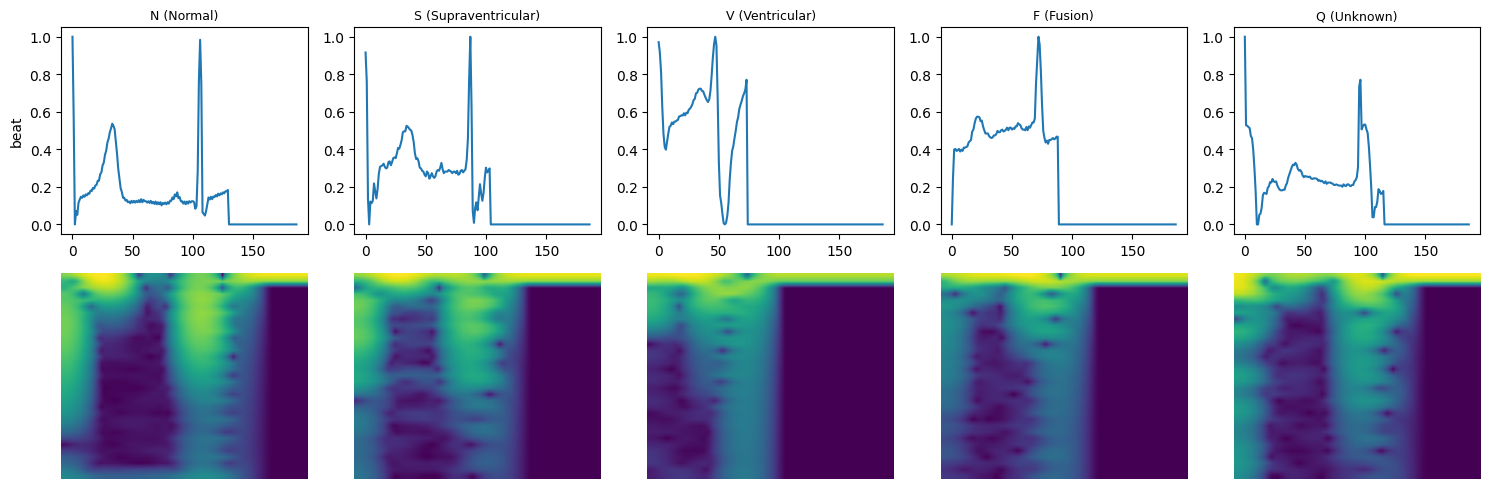

In [3]:
SPEC_CFG = [(32, 1), (64, 2), (128, 4)]       # (n_fft, hop) per channel
_win = {}
def _window(n):
    if n not in _win:
        _win[n] = torch.hann_window(n, device=device)
    return _win[n]

@torch.no_grad()
def to_image(x, size=CFG["img_size"]):
    # x: (B, 187) float tensor on GPU -> (B, 3, size, size)
    with torch.autocast("cuda", enabled=False):          # STFT in float32
        x = x.float()
        x = x - x.mean(dim=1, keepdim=True)              # remove DC offset
        chans = []
        for n_fft, hop in SPEC_CFG:
            S = torch.stft(x, n_fft=n_fft, hop_length=hop, win_length=n_fft,
                           window=_window(n_fft), center=True, return_complex=True).abs()
            S = torch.log1p(20.0 * S).unsqueeze(1)       # log-magnitude
            chans.append(F.interpolate(S, size=(size, size), mode="bilinear", align_corners=False))
        img = torch.cat(chans, 1)
        m = img.mean(dim=(2, 3), keepdim=True)
        s = img.std(dim=(2, 3), keepdim=True) + 1e-5
        return (img - m) / s                             # per-sample, per-channel standardisation

@torch.no_grad()
def augment(x):
    # light, physiologically plausible augmentation (training only)
    B = x.size(0)
    x = x * (1 + 0.1 * (torch.rand(B, 1, device=x.device) * 2 - 1))   # amplitude +-10%
    x = x + 0.01 * torch.randn_like(x)                                # sensor noise
    x = torch.roll(x, shifts=random.randint(-6, 6), dims=1)           # small time shift
    return x

# quick visual sanity check: one example per class
fig, ax = plt.subplots(2, NUM_CLASSES, figsize=(3 * NUM_CLASSES, 5))
for c in range(NUM_CLASSES):
    i = int((ytr_g == c).nonzero()[0])
    ax[0, c].plot(Xtr_g[i].cpu().numpy()); ax[0, c].set_title(CLASSES[c], fontsize=9)
    ax[1, c].imshow(to_image(Xtr_g[i:i+1])[0, 1].cpu().numpy(), aspect="auto"); ax[1, c].axis("off")
ax[0, 0].set_ylabel("beat"); plt.tight_layout(); plt.show()

## 4. Model
ImageNet-pretrained ConvNeXt-Atto (~3.7M params) with a new 5-class head, mixed precision, multi-GPU.

In [4]:
base_model = timm.create_model(
    CFG["model_name"], pretrained=True, num_classes=NUM_CLASSES,
    drop_rate=CFG["drop_rate"], drop_path_rate=CFG["drop_path_rate"],
).to(device).to(memory_format=torch.channels_last)
model = nn.DataParallel(base_model) if n_gpu > 1 else base_model
print(f"params: {sum(p.numel() for p in base_model.parameters())/1e6:.2f}M | GPUs used: {max(n_gpu,1)}")

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.8MB            

model.safetensors: downloading bytes:           |  0.00B            

params: 3.38M | GPUs used: 2


## 5. Training
Each epoch draws `samples_per_epoch` beats with class-rebalanced sampling. Per epoch we log: train loss, **clean** train accuracy (eval mode, no augmentation, natural distribution), val accuracy and val macro-F1. Best epoch = highest val macro-F1.

In [5]:
from tqdm.auto import tqdm

counts = np.bincount(y_tr, minlength=NUM_CLASSES)
w_class = 1.0 / counts.astype(np.float64) ** CFG["sampler_power"]
w_sample = torch.tensor(w_class[y_tr], dtype=torch.float32, device=device)

criterion = nn.CrossEntropyLoss(label_smoothing=CFG["label_smoothing"])
BS = CFG["batch_size"]
steps_per_epoch = CFG["samples_per_epoch"] // BS
opt = torch.optim.AdamW(model.parameters(), lr=CFG["max_lr"], weight_decay=CFG["weight_decay"])
sched = torch.optim.lr_scheduler.OneCycleLR(
    opt, max_lr=CFG["max_lr"], total_steps=CFG["epochs"] * steps_per_epoch, pct_start=0.15)
scaler = torch.amp.GradScaler("cuda")

@torch.no_grad()
def predict_logits(X, bs=1024):
    model.eval(); out = []
    for i in range(0, len(X), bs):
        img = to_image(X[i:i + bs]).contiguous(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            out.append(model(img).float())
    return torch.cat(out)

def gpu_mem():
    return " ".join(f"GPU{i}:{torch.cuda.memory_allocated(i)/1e9:.1f}GB" for i in range(n_gpu))

hist = {k: [] for k in ["train_loss", "train_acc_clean", "val_loss", "val_acc", "val_f1"]}
clean_idx = torch.randperm(len(Xtr_g), device=device)[:10000]
best_f1, best_state, bad_epochs, best_epoch = -1.0, None, 0, 0

print(f"[start] {steps_per_epoch} steps/epoch x {CFG['epochs']} epochs | batch {BS} | "
      f"img {CFG['img_size']} | {n_gpu} GPU(s)")

# ---- warm-up timing: first steps are slow (cuDNN autotune), this tells you the real speed ----
print("[warm-up] running 3 test steps (first one is slow, this is normal)...")
model.train()
for k in range(3):
    t = time.time()
    b = torch.multinomial(w_sample, BS, replacement=True)
    img = to_image(augment(Xtr_g[b])).contiguous(memory_format=torch.channels_last)
    with torch.autocast("cuda", dtype=torch.float16):
        loss = criterion(model(img).float(), ytr_g[b])
    opt.zero_grad(set_to_none=True)
    scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    torch.cuda.synchronize()
    dt = time.time() - t
    print(f"   step {k+1}: {dt:.2f}s")
est_epoch = dt * steps_per_epoch
print(f"[estimate] ~{est_epoch:.0f}s per epoch of training -> ~{est_epoch*CFG['epochs']/60:.0f} min for "
      f"{CFG['epochs']} epochs (early stopping / time cap may end sooner). {gpu_mem()}\n")

t0 = time.time()
for epoch in range(1, CFG["epochs"] + 1):
    model.train()
    idx = torch.multinomial(w_sample, steps_per_epoch * BS, replacement=True)
    run = torch.zeros((), device=device)
    t_ep = time.time()
    bar = tqdm(range(steps_per_epoch), desc=f"Epoch {epoch:02d}/{CFG['epochs']} train", leave=False)
    for s in bar:
        b = idx[s * BS:(s + 1) * BS]
        img = to_image(augment(Xtr_g[b])).contiguous(memory_format=torch.channels_last)
        with torch.autocast("cuda", dtype=torch.float16):
            loss = criterion(model(img).float(), ytr_g[b])
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        run += loss.detach()
        if s % 10 == 0:
            bar.set_postfix(loss=f"{loss.item():.3f}", lr=f"{sched.get_last_lr()[0]:.1e}")
    train_time = time.time() - t_ep

    print(f"   [eval] validating on {len(Xval_g)} beats...", end=" ")
    vl = predict_logits(Xval_g)
    vp = vl.argmax(1).cpu().numpy()
    val_acc = accuracy_score(y_val, vp)
    val_f1 = f1_score(y_val, vp, average="macro")
    val_loss = F.cross_entropy(vl, yval_g).item()
    tr_acc = (predict_logits(Xtr_g[clean_idx]).argmax(1) == ytr_g[clean_idx]).float().mean().item()
    print("done")

    hist["train_loss"].append(run.item() / steps_per_epoch)
    hist["train_acc_clean"].append(tr_acc); hist["val_loss"].append(val_loss)
    hist["val_acc"].append(val_acc); hist["val_f1"].append(val_f1)

    elapsed = (time.time() - t0) / 60
    per_epoch = elapsed / epoch
    eta = per_epoch * (CFG["epochs"] - epoch)
    flag = ""
    if val_f1 > best_f1 + 1e-4:
        best_f1, best_epoch, bad_epochs = val_f1, epoch, 0
        best_state = {k: v.detach().cpu().clone() for k, v in base_model.state_dict().items()}
        flag = "  <- BEST (saved)"
    else:
        bad_epochs += 1
    print(f"ep {epoch:02d} | loss {hist['train_loss'][-1]:.4f} | train_acc {tr_acc:.4f} | "
          f"val_acc {val_acc:.4f} | val_F1 {val_f1:.4f} | {train_time:.0f}s train | "
          f"{elapsed:.1f} min used | ETA ~{eta:.0f} min | no-improve {bad_epochs}/{CFG['patience']}{flag}")
    if bad_epochs >= CFG["patience"]:
        print("[stop] early stopping, val macro-F1 stopped improving."); break
    if elapsed > CFG["time_budget_min"]:
        print("[stop] time budget reached."); break

base_model.load_state_dict(best_state)
print(f"\n[done] restored best epoch {best_epoch} (val macro-F1 {best_f1:.4f}). "
      f"Total {(time.time()-t0)/60:.1f} min")

[start] 117 steps/epoch x 30 epochs | batch 256 | img 224 | 2 GPU(s)
[warm-up] running 3 test steps (first one is slow, this is normal)...
   step 1: 16.35s
   step 2: 0.45s
   step 3: 0.20s
[estimate] ~23s per epoch of training -> ~11 min for 30 epochs (early stopping / time cap may end sooner). GPU0:0.3GB GPU1:0.0GB



Epoch 01/30 train:   0%|          | 0/117 [00:00<?, ?it/s]

   [eval] validating on 8756 beats... done
ep 01 | loss 1.0818 | train_acc 0.8319 | val_acc 0.8318 | val_F1 0.5867 | 24s train | 0.5 min used | ETA ~15 min | no-improve 0/6  <- BEST (saved)


Epoch 02/30 train:   0%|          | 0/117 [00:00<?, ?it/s]

   [eval] validating on 8756 beats... done
ep 02 | loss 0.6581 | train_acc 0.7914 | val_acc 0.7884 | val_F1 0.5786 | 24s train | 1.0 min used | ETA ~14 min | no-improve 1/6


Epoch 03/30 train:   0%|          | 0/117 [00:00<?, ?it/s]

... (51 outputs left out)

Epoch 29/30 train:   0%|          | 0/117 [00:00<?, ?it/s]

   [eval] validating on 8756 beats... done
ep 29 | loss 0.2398 | train_acc 0.9963 | val_acc 0.9873 | val_F1 0.9218 | 25s train | 15.2 min used | ETA ~1 min | no-improve 2/6


Epoch 30/30 train:   0%|          | 0/117 [00:00<?, ?it/s]

   [eval] validating on 8756 beats... done
ep 30 | loss 0.2375 | train_acc 0.9962 | val_acc 0.9872 | val_F1 0.9214 | 25s train | 15.7 min used | ETA ~0 min | no-improve 3/6

[done] restored best epoch 27 (val macro-F1 0.9274). Total 15.7 min


## 6. Probability calibration (temperature scaling)
Fitted on the **validation** set only. It does not change predicted classes, but makes the probabilities trustworthy for the late-fusion step.

In [6]:
val_logits = predict_logits(Xval_g)
T = torch.ones(1, device=device, requires_grad=True)
lbfgs = torch.optim.LBFGS([T], lr=0.1, max_iter=100)
def _closure():
    lbfgs.zero_grad()
    l = F.cross_entropy(val_logits / T.clamp(min=0.05), yval_g)
    l.backward(); return l
lbfgs.step(_closure)
TEMP = float(T.clamp(min=0.05).item())
print(f"temperature = {TEMP:.3f}")

temperature = 0.731


## 7. Final evaluation on the untouched test set

In [7]:
test_logits = predict_logits(Xte_g)
test_prob = F.softmax(test_logits / TEMP, dim=1).cpu().numpy()
test_pred = test_prob.argmax(1)

test_acc = accuracy_score(y_test, test_pred)
print(f"TEST accuracy          : {test_acc:.4f}")
print(f"TEST balanced accuracy : {balanced_accuracy_score(y_test, test_pred):.4f}")
print(f"TEST macro-F1          : {f1_score(y_test, test_pred, average='macro'):.4f}\n")
print(classification_report(y_test, test_pred, target_names=CLASSES, digits=4))

# ---- overfitting check: clean train vs val vs test ----
val_acc_final = accuracy_score(y_val, predict_logits(Xval_g).argmax(1).cpu().numpy())
train_acc_final = (predict_logits(Xtr_g[clean_idx]).argmax(1) == ytr_g[clean_idx]).float().mean().item()
gap = pd.DataFrame({"split": ["train (clean)", "val", "test"],
                    "accuracy": [train_acc_final, val_acc_final, test_acc]})
print(gap.to_string(index=False))
print(f"\ntrain - test gap: {100*(train_acc_final - test_acc):.2f} points "
      f"({'small -> no sign of overfitting' if train_acc_final - test_acc < 0.02 else 'check regularisation'})")

recalls = f1_score(y_test, test_pred, average=None)
print("\nTarget check (>= 94%):")
print("  overall accuracy :", "PASS" if test_acc >= 0.94 else "FAIL", f"({test_acc:.4f})")
for c, r in zip(CLASSES, recalls):
    print(f"  F1 {c:<22}:", "PASS" if r >= 0.94 else "below 94", f"({r:.4f})")

TEST accuracy          : 0.9863
TEST balanced accuracy : 0.9306
TEST macro-F1          : 0.9265

                      precision    recall  f1-score   support

          N (Normal)     0.9936    0.9928    0.9932     18118
S (Supraventricular)     0.8610    0.8687    0.8648       556
     V (Ventricular)     0.9515    0.9620    0.9567      1448
          F (Fusion)     0.8095    0.8395    0.8242       162
         Q (Unknown)     0.9975    0.9900    0.9938      1608

            accuracy                         0.9863     21892
           macro avg     0.9226    0.9306    0.9265     21892
        weighted avg     0.9864    0.9863    0.9863     21892

        split  accuracy
train (clean)  0.996300
          val  0.987666
         test  0.986251

train - test gap: 1.00 points (small -> no sign of overfitting)

Target check (>= 94%):
  overall accuracy : PASS (0.9863)
  F1 N (Normal)            : PASS (0.9932)
  F1 S (Supraventricular)  : below 94 (0.8648)
  F1 V (Ventricular)       : PAS

## 8. Plots: training curves, confusion matrix, ROC

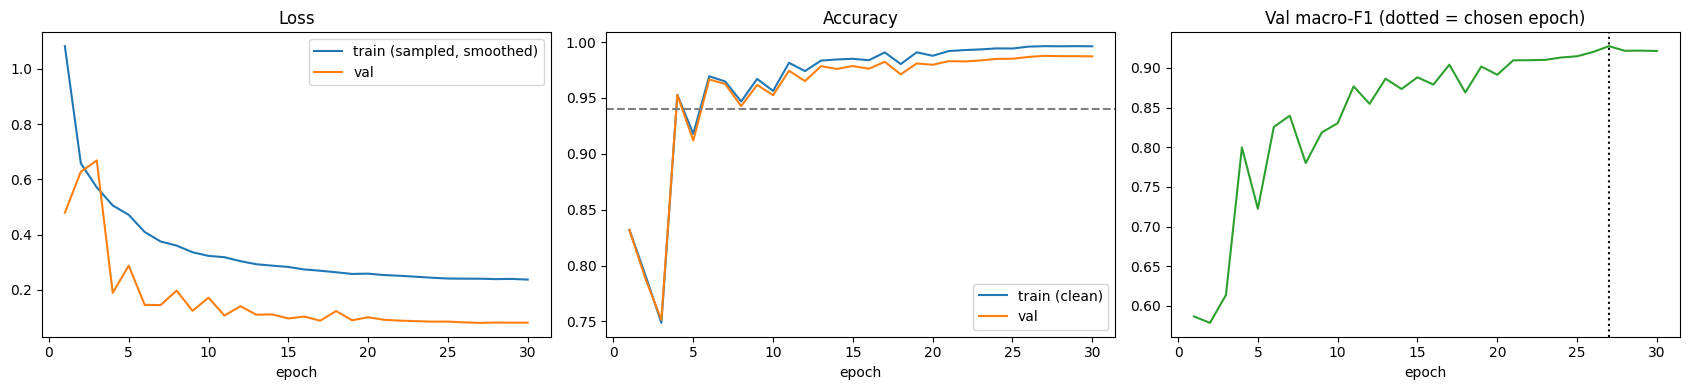

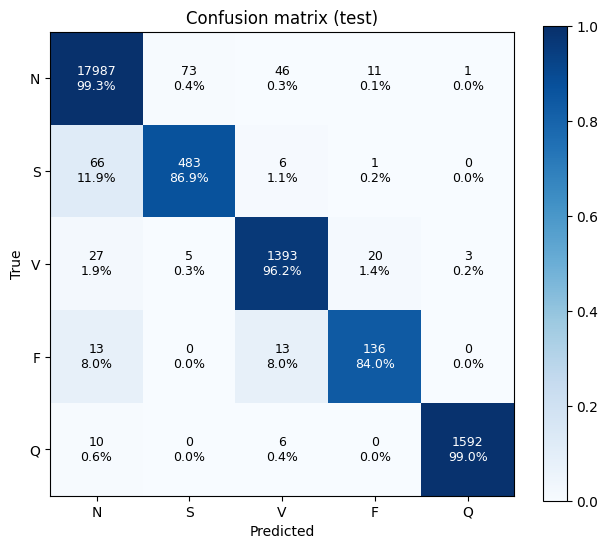

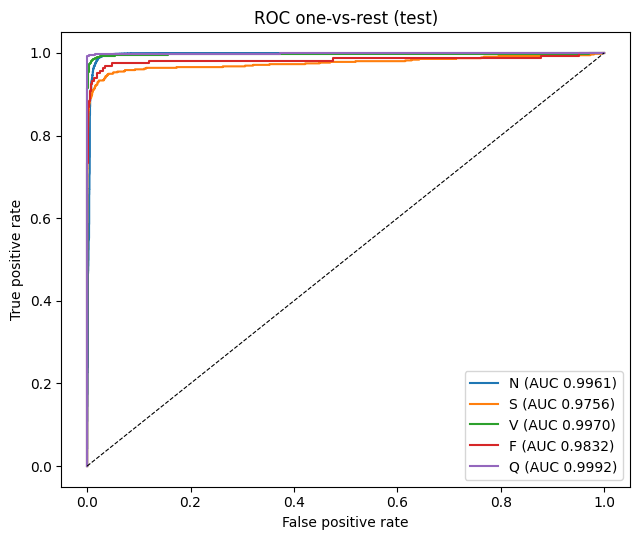

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ep = range(1, len(hist["val_acc"]) + 1)
ax[0].plot(ep, hist["train_loss"], label="train (sampled, smoothed)"); ax[0].plot(ep, hist["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
ax[1].plot(ep, hist["train_acc_clean"], label="train (clean)"); ax[1].plot(ep, hist["val_acc"], label="val")
ax[1].axhline(0.94, ls="--", c="gray"); ax[1].set_title("Accuracy"); ax[1].set_xlabel("epoch"); ax[1].legend()
ax[2].plot(ep, hist["val_f1"], c="tab:green"); ax[2].axvline(best_epoch, ls=":", c="k")
ax[2].set_title("Val macro-F1 (dotted = chosen epoch)"); ax[2].set_xlabel("epoch")
plt.tight_layout(); plt.savefig("/kaggle/working/training_curves.png", dpi=150); plt.show()

# confusion matrix (counts + row-normalised %)
cm = confusion_matrix(y_test, test_pred)
cmn = cm / cm.sum(1, keepdims=True)
short = ["N", "S", "V", "F", "Q"]
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cmn, cmap="Blues", vmin=0, vmax=1)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, f"{cm[i,j]}\n{cmn[i,j]*100:.1f}%", ha="center", va="center",
                color="white" if cmn[i, j] > 0.5 else "black", fontsize=9)
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(short); ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(short)
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title("Confusion matrix (test)")
plt.colorbar(im); plt.tight_layout(); plt.savefig("/kaggle/working/confusion_matrix.png", dpi=150); plt.show()

# one-vs-rest ROC
Y = label_binarize(y_test, classes=list(range(NUM_CLASSES)))
plt.figure(figsize=(6.5, 5.5))
for c in range(NUM_CLASSES):
    fpr, tpr, _ = roc_curve(Y[:, c], test_prob[:, c])
    plt.plot(fpr, tpr, label=f"{short[c]} (AUC {auc(fpr, tpr):.4f})")
plt.plot([0, 1], [0, 1], "k--", lw=0.8); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("ROC one-vs-rest (test)"); plt.legend(); plt.tight_layout()
plt.savefig("/kaggle/working/roc_curves.png", dpi=150); plt.show()

## 9. Save the final model + reusable inference module
`ecg_inference.py` is a standalone loader: copy it with `ecg_convnext_atto.pth` into your Gradio project. It returns calibrated 5-class probabilities and an abnormal-risk score (`1 - P(Normal)`) for late fusion.

In [9]:
os.makedirs("/kaggle/working", exist_ok=True)
torch.save({
    "state_dict": {k: v.cpu() for k, v in base_model.state_dict().items()},
    "classes": CLASSES,
    "temperature": TEMP,
    "config": {"model_name": CFG["model_name"], "img_size": CFG["img_size"], "spec_cfg": SPEC_CFG},
}, "/kaggle/working/ecg_convnext_atto.pth")

INFER_SRC = r"""
# ecg_inference.py : standalone inference for the ConvNeXt-Atto ECG beat classifier
# Input : beats of 187 samples (MIT-BIH style, 125 Hz, one heartbeat, amplitude scaled to 0-1)
# Output: calibrated probabilities for [N, S, V, F, Q] and an abnormal-risk score (1 - P(N))
import numpy as np, torch, torch.nn.functional as F, timm

class ECGClassifier:
    def __init__(self, path="ecg_convnext_atto.pth", device=None):
        self.device = torch.device(device or ("cuda" if torch.cuda.is_available() else "cpu"))
        ck = torch.load(path, map_location="cpu")
        self.classes, self.T = ck["classes"], ck["temperature"]
        self.size, self.spec = ck["config"]["img_size"], ck["config"]["spec_cfg"]
        self.model = timm.create_model(ck["config"]["model_name"], pretrained=False, num_classes=len(self.classes))
        self.model.load_state_dict(ck["state_dict"])
        self.model.to(self.device).eval()
        self.win = {n: torch.hann_window(n, device=self.device) for n, _ in self.spec}

    def _to_image(self, x):
        x = x - x.mean(dim=1, keepdim=True)
        chans = []
        for n_fft, hop in self.spec:
            S = torch.stft(x, n_fft=n_fft, hop_length=hop, win_length=n_fft, window=self.win[n_fft],
                           center=True, return_complex=True).abs()
            S = torch.log1p(20.0 * S).unsqueeze(1)
            chans.append(F.interpolate(S, size=(self.size, self.size), mode="bilinear", align_corners=False))
        img = torch.cat(chans, 1)
        return (img - img.mean(dim=(2, 3), keepdim=True)) / (img.std(dim=(2, 3), keepdim=True) + 1e-5)

    @torch.no_grad()
    def predict_proba(self, beats):
        x = torch.as_tensor(np.asarray(beats, dtype=np.float32), device=self.device)
        if x.ndim == 1:
            x = x[None]
        out = []
        for i in range(0, len(x), 256):
            logits = self.model(self._to_image(x[i:i + 256]))
            out.append(F.softmax(logits / self.T, dim=1).cpu().numpy())
        return np.concatenate(out)

    def risk_score(self, beats):
        return 1.0 - self.predict_proba(beats)[:, 0]
"""
with open("/kaggle/working/ecg_inference.py", "w") as f:
    f.write(INFER_SRC.strip() + "\n")

# ---- sanity check: the standalone module must reproduce the notebook's predictions ----
sys.path.insert(0, "/kaggle/working")
from ecg_inference import ECGClassifier
clf = ECGClassifier("/kaggle/working/ecg_convnext_atto.pth")
chk = clf.predict_proba(X_test[:2000]).argmax(1)
print("standalone module matches notebook predictions:", float((chk == test_pred[:2000]).mean()))
print("example risk scores:", np.round(clf.risk_score(X_test[:5]), 4), "| true labels:", y_test[:5])

# ---- optional ONNX export of the network (expects the 3x224x224 spectrogram image as input) ----
try:
    import copy
    m_cpu = copy.deepcopy(base_model).cpu().eval()
    torch.onnx.export(m_cpu, torch.randn(1, 3, CFG["img_size"], CFG["img_size"]),
                      "/kaggle/working/ecg_convnext_atto.onnx", input_names=["image"],
                      output_names=["logits"], dynamic_axes={"image": {0: "batch"}, "logits": {0: "batch"}},
                      opset_version=17)
    print("ONNX exported")
except Exception as e:
    print("ONNX export skipped:", repr(e)[:150])

print("\nSaved to /kaggle/working:", sorted(os.listdir("/kaggle/working")))

standalone module matches notebook predictions: 1.0
example risk scores: [0.0072 0.0082 0.0072 0.007  0.0077] | true labels: [0 0 0 0 0]
ONNX export skipped: ModuleNotFoundError("No module named 'onnxscript'")

Saved to /kaggle/working: ['__notebook__.ipynb', '__pycache__', 'confusion_matrix.png', 'ecg_convnext_atto.pth', 'ecg_inference.py', 'roc_curves.png', 'training_curves.png']


## 10. How to use in the project
```python
from ecg_inference import ECGClassifier
clf = ECGClassifier("ecg_convnext_atto.pth")
probs = clf.predict_proba(beat_187_samples)    # shape (N, 5): [N, S, V, F, Q]
ecg_risk = clf.risk_score(beat_187_samples)    # 1 - P(Normal), feeds late fusion
```
**Late fusion idea:** `final_risk = w * xgb_risk + (1 - w) * ecg_risk` (choose `w` on a validation set), or feed `[xgb_prob, ecg_probs]` into a small logistic regression.

**Notes**
- The official MIT-BIH split here is beat-level, not patient-level, so scores are optimistic compared with unseen patients. State this in your report.
- Inputs must be single beats resampled to 187 samples at 125 Hz, amplitude scaled to 0-1, like the dataset.
- If accuracy or per-class F1 falls short of 94%: raise `sampler_power` to 1.0, raise `samples_per_epoch`, or train a second seed and average the probabilities.

In [10]:

import os
import zipfile
from IPython.display import FileLink, display

files = [
    "ecg_convnext_atto.pth",
    "ecg_inference.py",
    "ecg_convnext_atto.onnx"
]

zip_path = "/kaggle/working/ecg_model_bundle.zip"

with zipfile.ZipFile(zip_path, "w") as z:
    for filename in files:
        path = f"/kaggle/working/{filename}"

        if os.path.exists(path):
            z.write(path, filename)
            print("Added:", filename)
        else:
            print("Not found:", filename)

print("\nDownload your model:")
display(FileLink(zip_path))


Added: ecg_convnext_atto.pth
Added: ecg_inference.py
Not found: ecg_convnext_atto.onnx

Download your model:


/kaggle/working/ecg_model_bundle.zip